In [1]:
from pathlib import Path
import sys

import torch

ROOT = Path("/home/ibm-user/shared/trustpause")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.train_seq import SEQ_FEATURE_NAMES, SequenceGRU

MODEL_PATH = ROOT / "models" / "seq.pt"
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False,
)

model = SequenceGRU(
    input_size=checkpoint["input_size"],
    hidden_size=checkpoint["hidden_size"],
)
model.load_state_dict(checkpoint["state_dict"])
model.eval()

print("model_path:", MODEL_PATH)
print("sequence_length:", checkpoint["sequence_length"])
print("feature_names:", SEQ_FEATURE_NAMES)
print("ensemble_xgb_weight:", checkpoint["ensemble_xgb_weight"])
print("saved_splits:", list(checkpoint["results"]))

model_path: /home/ibm-user/shared/trustpause/models/seq.pt
sequence_length: 10
feature_names: ['log_amount', 'time_gap_minutes', 'direction', 'counterparty_novelty', 'payment_format', 'cross_currency']
ensemble_xgb_weight: 1.0
saved_splits: ['val', 'test']


In [2]:
import pandas as pd

print("--- split results ---")
results_table = pd.DataFrame(checkpoint["results"]).T
display(results_table)

print("--- CPU vs NNPA latency ---")
latency_table = pd.DataFrame(checkpoint["benchmark"]).T
display(latency_table)

--- split results ---


,rows,positives,seq_pr_auc,xgb_pr_auc,ensemble_pr_auc,ensemble_xgb_weight
val,965524.0,1036.0,0.010882,0.360805,0.360805,1.0
test,862792.0,956.0,0.005142,0.254146,0.254146,1.0


--- CPU vs NNPA latency ---


,p50_ms,p95_ms
cpu_batch_1,0.171,0.192
cpu_batch_64,1.693,1.870
nnpa_batch_1,0.082,0.093
nnpa_batch_64,0.131,0.140


latency_chart: /home/ibm-user/shared/trustpause/screenshots/sequence_latency.png


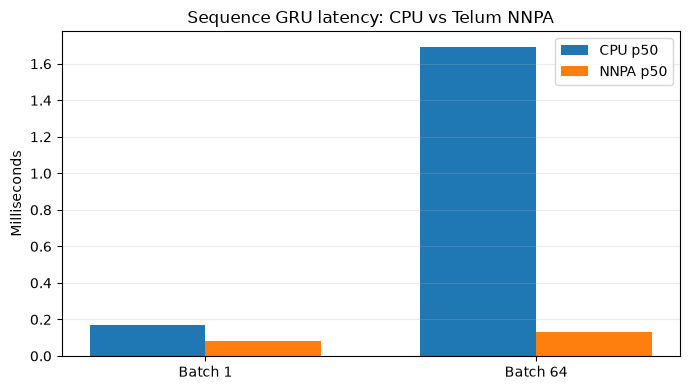

--- lscpu NNPA evidence ---
nnpa


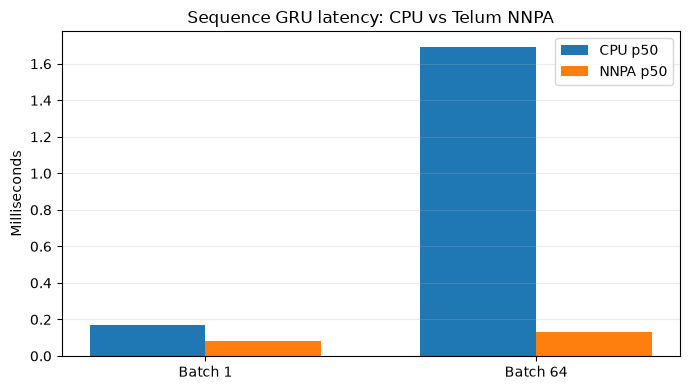

In [3]:
import subprocess

import matplotlib.pyplot as plt
import numpy as np

latency = checkpoint["benchmark"]

labels = ["Batch 1", "Batch 64"]
cpu_p50 = [
    latency["cpu_batch_1"]["p50_ms"],
    latency["cpu_batch_64"]["p50_ms"],
]
nnpa_p50 = [
    latency["nnpa_batch_1"]["p50_ms"],
    latency["nnpa_batch_64"]["p50_ms"],
]

positions = np.arange(len(labels))
width = 0.35

fig, axis = plt.subplots(figsize=(7, 4))
axis.bar(
    positions - width / 2,
    cpu_p50,
    width,
    label="CPU p50",
)
axis.bar(
    positions + width / 2,
    nnpa_p50,
    width,
    label="NNPA p50",
)
axis.set_title("Sequence GRU latency: CPU vs Telum NNPA")
axis.set_ylabel("Milliseconds")
axis.set_xticks(positions)
axis.set_xticklabels(labels)
axis.legend()
axis.grid(axis="y", alpha=0.25)
fig.tight_layout()

chart_path = ROOT / "screenshots" / "sequence_latency.png"
fig.savefig(chart_path, dpi=160)
print("latency_chart:", chart_path)
display(fig)

print("--- lscpu NNPA evidence ---")
lscpu_result = subprocess.run(
    ["bash", "-lc", "lscpu | grep -io nnpa"],
    capture_output=True,
    text=True,
)
print(lscpu_result.stdout.strip() or "NNPA text not found")

In [4]:
import copy

import torch_nnpa

torch.manual_seed(7)

probe_cpu = copy.deepcopy(model).eval().half()
probe_inputs = torch.randn(1, 10, 6, dtype=torch.float16)

with torch.inference_mode():
    cpu_output = probe_cpu(probe_inputs)

probe_nnpa = copy.deepcopy(model).eval().half().to(torch_nnpa.device())
nnpa_inputs = probe_inputs.to(torch_nnpa.device())

with torch.inference_mode():
    nnpa_output = probe_nnpa(nnpa_inputs).to("cpu")

max_difference = (
    cpu_output.float() - nnpa_output.float()
).abs().max().item()

print("cpu_output:", cpu_output.float().tolist())
print("nnpa_output:", nnpa_output.float().tolist())
print("max_absolute_difference:", max_difference)
print(
    "outputs_close:",
    torch.allclose(
        cpu_output.float(),
        nnpa_output.float(),
        rtol=1e-2,
        atol=1e-2,
    ),
)

cpu_output: [0.365478515625]
nnpa_output: [0.365234375]
max_absolute_difference: 0.000244140625
outputs_close: True
